# DTU dataset, all rooms pooled (anechoic, mild and high reverberation): forward models

Converging evidence from an independent two-talker EEG dataset: Fuglsang, Dau & Hjortkjaer 2017, NeuroImage 156:435-444 (Zenodo 1199011; 18 subjects, 64-channel EEG, two talkers at +-60 degrees, attend one). That paper decoded attention; here the same data go through the forward models of this project, cell for cell as `diotic.ipynb`.

**How the data were prepared** (`dtu/dtu_pipeline.py`, on the cluster; run from `dtu.ipynb`), aligned with this project step for step:
- EEG: the raw recordings, preprocessed as this project's pipeline: bad channels by neighbour correlation, 0.5-20 Hz, mastoid reference, extended-infomax ICA with ICLabel (eye blinks, heart beats at >= 0.9), 64 Hz; trials cut at the trigger events as the authors' script does
- Trials: from the authors' trial table (stories, attended talker, single or two talkers, room)
- Predictors: 8-band gammatone envelope and onsets, made exactly as this project's; the mixture from the two stories summed (the rooms were simulated at presentation, so the exact mixture at the ears is not available)
- TRFs: the same boosting settings (-100 to 400 ms, 50 ms basis, l1, cross-validated)
- Tests: as this project's two-talker notebooks

**ROI:** this project's clean-speech ROI (`roi.txt`), found from the cocktail clean-speech whole-scalp tests (`clean.ipynb`). Every model test below runs within it (one-tailed TFCE in the ROI, and the ROI-averaged t-test), as in this project's two-talker notebooks, and every response function is averaged over it.

**Results come from the cluster**: run `dtu_run()` in `dtu.ipynb` first; this notebook only reads them.

In [67]:
# Reloads the code every time it runs, so changes pulled from GitHub take effect without
# restarting the kernel (Run All is enough).
import importlib, sys
for _module in ('experiment', 'parameters'):
    if getattr(sys.modules.get(_module), '__spec__', None):
        importlib.reload(sys.modules[_module])
from parameters import *

## DTU, all rooms pooled (anechoic, mild and high reverberation)

In [68]:
# Reads this room's results from the cluster and sets the ROI: this project's clean-speech ROI (roi.txt),
# found from the cocktail clean-speech whole-scalp tests. Every test below runs within it.
ROI = dtu_setup('all')

DTU all: 18 subjects, 60 trials of 50 s each.
ROI, this project's clean-speech ROI (18 sensors): AF3, F1, F3, F5, F7, FC5, FC3, C1, C3, C5, AF4, AFz, F6, FT8, FC6, FC4, FC2, C2
Every model test within the ROI above; ROI means and TRFs in the same ROI.


In [69]:
# All subjects' full-model TRFs, with the same columns as the cocktail notebooks' data_full
data_full = dtu_trfs('all')

<small>

**Stream-level tests: each stream's envelope + onsets removed together**

- A stream = one talker's (or the mixture's) envelope + onsets
- Asks whether the brain tracks that stream at all, beyond the other two
- Can be significant when neither the envelope nor the onsets alone are

</small>

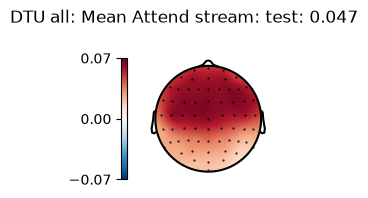

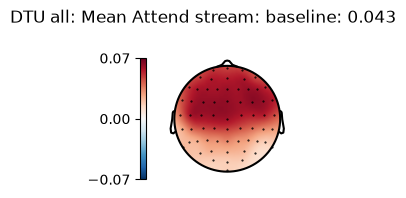

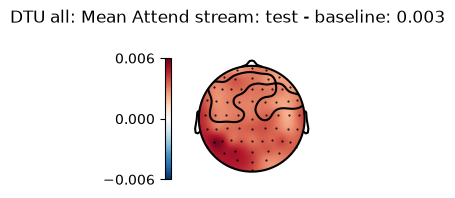

In [70]:
# Attend stream (envelope + onsets) unique contribution (DTU all)
data, diff, result = dtu_model_test('Attend stream', 'all')
show_topomap_trio(data, diff, result, 'Attend stream', 'DTU all', None)

In [71]:
display(result)
print(f"Attend stream (DTU all): TFCE {tfce_summary(result)}")
ttest = test.TTestOneSample(f'roi_{METRIC}', data=diff, tail=1)
print(f"Attend stream (DTU all): ROI model comparison t({ttest.df}) = {ttest.t:.3f}, p = {ttest.p:.4f}")

<TTestRelated 'r', 'model', 'test', 'baseline', 'subject' (n=18), tail=1, samples=10000, tfce=True, p < .001>

Attend stream (DTU all): TFCE t_max = 6.09, p < 0.001
Attend stream (DTU all): ROI model comparison t(17) = 5.487, p = 0.0000


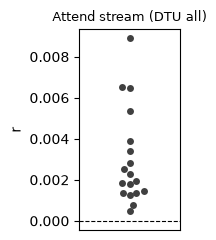

In [72]:
p = show_subject_swarm(diff, 'Attend stream', 'DTU all')

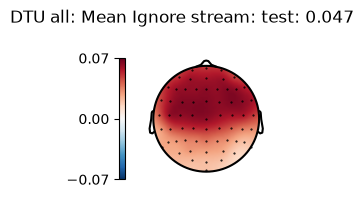

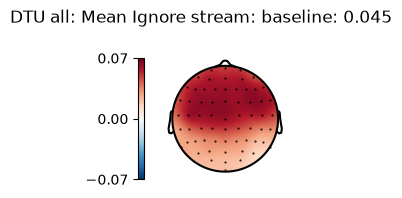

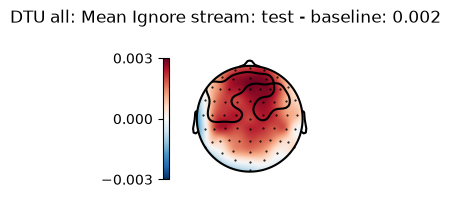

In [73]:
# Ignore stream (envelope + onsets) unique contribution (DTU all)
data, diff, result = dtu_model_test('Ignore stream', 'all')
show_topomap_trio(data, diff, result, 'Ignore stream', 'DTU all', None)

In [74]:
display(result)
print(f"Ignore stream (DTU all): TFCE {tfce_summary(result)}")
ttest = test.TTestOneSample(f'roi_{METRIC}', data=diff, tail=1)
print(f"Ignore stream (DTU all): ROI model comparison t({ttest.df}) = {ttest.t:.3f}, p = {ttest.p:.4f}")

<TTestRelated 'r', 'model', 'test', 'baseline', 'subject' (n=18), tail=1, samples=10000, tfce=True, p < .001>

Ignore stream (DTU all): TFCE t_max = 4.51, p < 0.001
Ignore stream (DTU all): ROI model comparison t(17) = 4.385, p = 0.0002


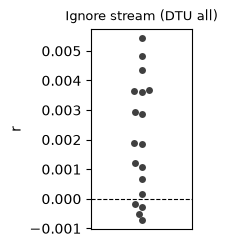

In [75]:
p = show_subject_swarm(diff, 'Ignore stream', 'DTU all')

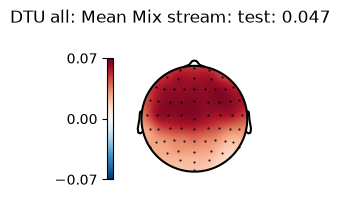

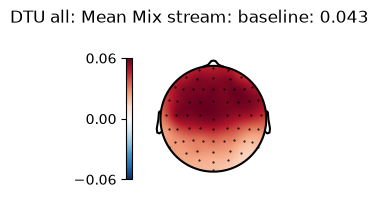

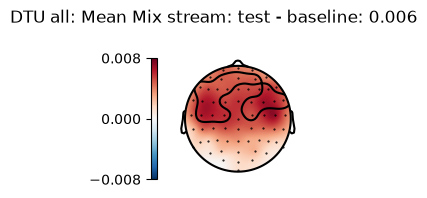

In [76]:
# Mix stream (envelope + onsets) unique contribution (DTU all)
data, diff, result = dtu_model_test('Mix stream', 'all')
show_topomap_trio(data, diff, result, 'Mix stream', 'DTU all', None)

In [77]:
display(result)
print(f"Mix stream (DTU all): TFCE {tfce_summary(result)}")
ttest = test.TTestOneSample(f'roi_{METRIC}', data=diff, tail=1)
print(f"Mix stream (DTU all): ROI model comparison t({ttest.df}) = {ttest.t:.3f}, p = {ttest.p:.4f}")

<TTestRelated 'r', 'model', 'test', 'baseline', 'subject' (n=18), tail=1, samples=10000, tfce=True, p < .001>

Mix stream (DTU all): TFCE t_max = 12.19, p < 0.001
Mix stream (DTU all): ROI model comparison t(17) = 8.743, p = 0.0000


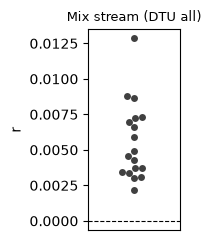

In [78]:
p = show_subject_swarm(diff, 'Mix stream', 'DTU all')

<small>

**Brodbeck et al. 2020: Two talkers, onset attend unique contribution**

- Attended onsets add predictive power: t_max = 6.32, p < 0.001
- All tests here are within the auditory cortex region
- Best overall model fit: r = 0.158

</small>

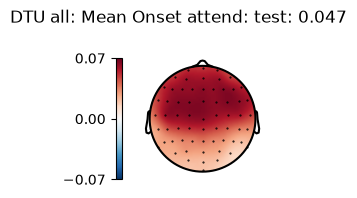

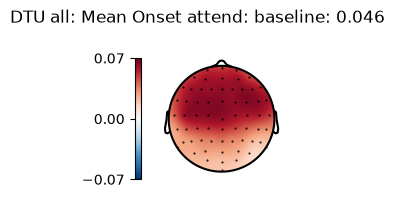

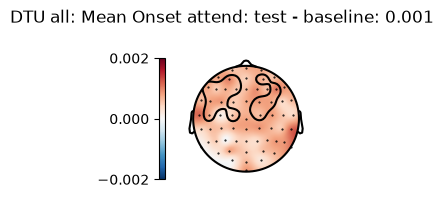

In [79]:
# Onset attend unique contribution (DTU all)
# Brodbeck et al. 2020 ran this comparison too: attended onsets unique contribution, t = 6.32, p < .001.
data, diff, result = dtu_model_test('Onset attend', 'all')
show_topomap_trio(data, diff, result, 'Onset attend', 'DTU all', None)

In [80]:
display(result)
print(f"Onset attend (DTU all): TFCE {tfce_summary(result)}")
ttest = test.TTestOneSample(f'roi_{METRIC}', data=diff, tail=1)
print(f"Onset attend (DTU all): ROI model comparison t({ttest.df}) = {ttest.t:.3f}, p = {ttest.p:.4f}")

<TTestRelated 'r', 'model', 'test', 'baseline', 'subject' (n=18), tail=1, samples=10000, tfce=True, p < .001>

Onset attend (DTU all): TFCE t_max = 4.73, p < 0.001
Onset attend (DTU all): ROI model comparison t(17) = 4.133, p = 0.0003


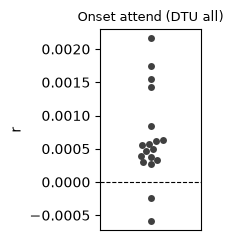

In [81]:
p = show_subject_swarm(diff, 'Onset attend', 'DTU all')

<small>

**Brodbeck et al. 2020: Two talkers, onset ignore unique contribution**

- Ignored onsets add predictive power: t_max = 6.70, p < 0.001
- Key finding: the ignored speaker is represented even after accounting for the mixture and the attended speaker

</small>

/Users/joshuaighalo/Github Repositories/cocktail-cortical/analysis/experiment.py:1063: UserWarning: Warning: converting a masked element to nan.
  mean_value = float(data.mean())


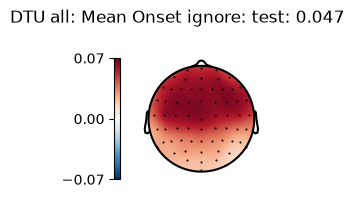

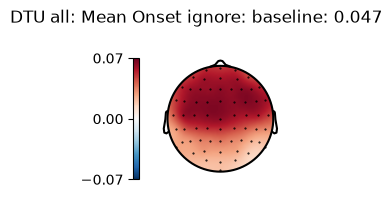

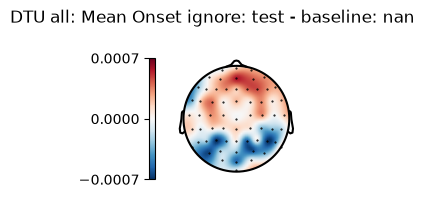

In [82]:
# Onset ignore unique contribution (DTU all)
# Brodbeck et al. 2020 ran this comparison too: ignored onsets unique contribution, t = 6.70, p < .001 - the ignored speaker is tracked separately.
data, diff, result = dtu_model_test('Onset ignore', 'all')
show_topomap_trio(data, diff, result, 'Onset ignore', 'DTU all', None)

In [83]:
display(result)
print(f"Onset ignore (DTU all): TFCE {tfce_summary(result)}")
ttest = test.TTestOneSample(f'roi_{METRIC}', data=diff, tail=1)
print(f"Onset ignore (DTU all): ROI model comparison t({ttest.df}) = {ttest.t:.3f}, p = {ttest.p:.4f}")

<TTestRelated 'r', 'model', 'test', 'baseline', 'subject' (n=18), tail=1, samples=10000, tfce=True, p = .112>

Onset ignore (DTU all): TFCE t_max = 2.46, p = 0.112
Onset ignore (DTU all): ROI model comparison t(17) = 1.540, p = 0.0710


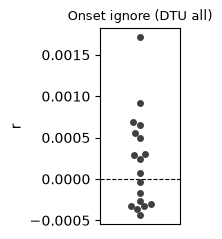

In [84]:
p = show_subject_swarm(diff, 'Onset ignore', 'DTU all')

<small>

**Brodbeck et al. 2020: Two talkers, onset mix unique contribution**

- Mixture onsets add predictive power: t_max = 8.61, p < 0.001

</small>

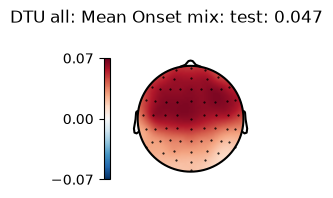

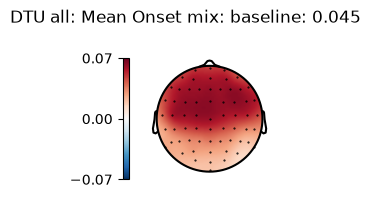

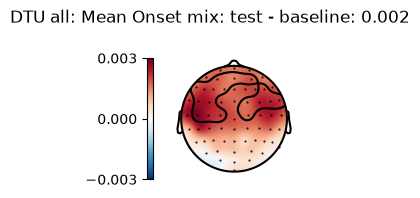

In [85]:
# Onset mix unique contribution (DTU all)
# Brodbeck et al. 2020 ran this comparison too: mixture onsets unique contribution, t = 8.61, p < .001.
data, diff, result = dtu_model_test('Onset mix', 'all')
show_topomap_trio(data, diff, result, 'Onset mix', 'DTU all', None)

In [86]:
display(result)
print(f"Onset mix (DTU all): TFCE {tfce_summary(result)}")
ttest = test.TTestOneSample(f'roi_{METRIC}', data=diff, tail=1)
print(f"Onset mix (DTU all): ROI model comparison t({ttest.df}) = {ttest.t:.3f}, p = {ttest.p:.4f}")

<TTestRelated 'r', 'model', 'test', 'baseline', 'subject' (n=18), tail=1, samples=10000, tfce=True, p < .001>

Onset mix (DTU all): TFCE t_max = 9.60, p < 0.001
Onset mix (DTU all): ROI model comparison t(17) = 7.438, p = 0.0000


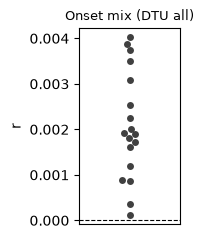

In [87]:
p = show_subject_swarm(diff, 'Onset mix', 'DTU all')

<small>

**Brodbeck et al. 2020: Two talkers, envelope attend unique contribution**

- Attended envelope adds predictive power: t_max = 7.37, p < 0.001

</small>

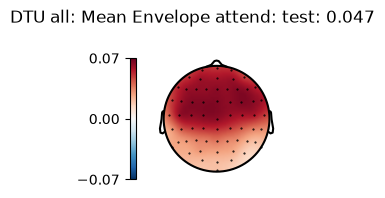

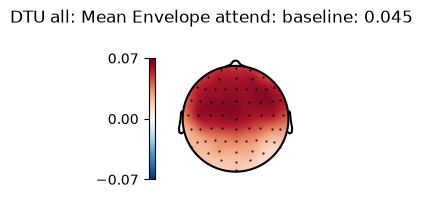

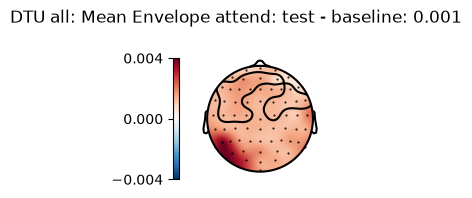

In [88]:
# Envelope attend unique contribution (DTU all)
# Brodbeck et al. 2020 ran this comparison too: attended envelope unique contribution, t = 7.37, p < .001.
data, diff, result = dtu_model_test('Envelope attend', 'all')
show_topomap_trio(data, diff, result, 'Envelope attend', 'DTU all', None)

In [89]:
display(result)
print(f"Envelope attend (DTU all): TFCE {tfce_summary(result)}")
ttest = test.TTestOneSample(f'roi_{METRIC}', data=diff, tail=1)
print(f"Envelope attend (DTU all): ROI model comparison t({ttest.df}) = {ttest.t:.3f}, p = {ttest.p:.4f}")

<TTestRelated 'r', 'model', 'test', 'baseline', 'subject' (n=18), tail=1, samples=10000, tfce=True, p < .001>

Envelope attend (DTU all): TFCE t_max = 4.43, p < 0.001
Envelope attend (DTU all): ROI model comparison t(17) = 3.684, p = 0.0009


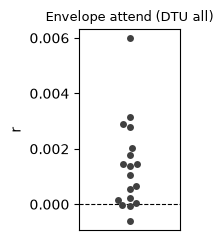

In [90]:
p = show_subject_swarm(diff, 'Envelope attend', 'DTU all')

<small>

**Brodbeck et al. 2020: Two talkers, envelope ignore unique contribution**

- Ignored envelope adds predictive power: t_max = 6.28, p < 0.001

</small>

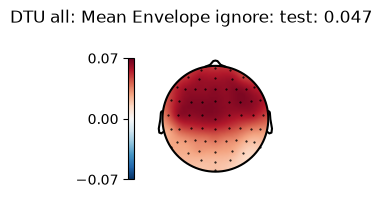

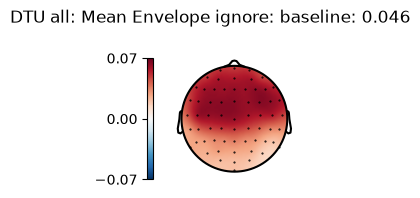

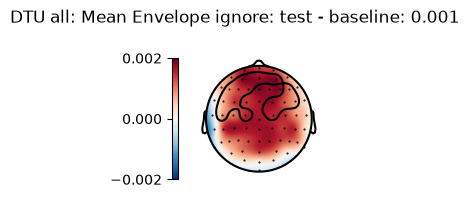

In [91]:
# Envelope ignore unique contribution (DTU all)
# Brodbeck et al. 2020 ran this comparison too: ignored envelope unique contribution, t = 6.28, p < .001 - the ignored speaker's envelope is tracked separately too.
data, diff, result = dtu_model_test('Envelope ignore', 'all')
show_topomap_trio(data, diff, result, 'Envelope ignore', 'DTU all', None)

In [92]:
display(result)
print(f"Envelope ignore (DTU all): TFCE {tfce_summary(result)}")
ttest = test.TTestOneSample(f'roi_{METRIC}', data=diff, tail=1)
print(f"Envelope ignore (DTU all): ROI model comparison t({ttest.df}) = {ttest.t:.3f}, p = {ttest.p:.4f}")

<TTestRelated 'r', 'model', 'test', 'baseline', 'subject' (n=18), tail=1, samples=10000, tfce=True, p < .001>

Envelope ignore (DTU all): TFCE t_max = 4.27, p < 0.001
Envelope ignore (DTU all): ROI model comparison t(17) = 3.311, p = 0.0021


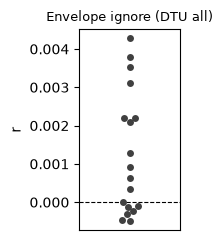

In [93]:
p = show_subject_swarm(diff, 'Envelope ignore', 'DTU all')

<small>

**Brodbeck et al. 2020: Two talkers, envelope mix unique contribution**

- Mixture envelope adds predictive power: t_max = 5.70, p < 0.001

</small>

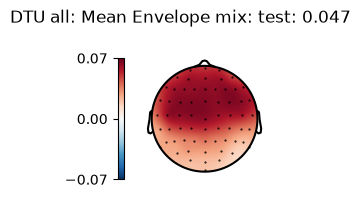

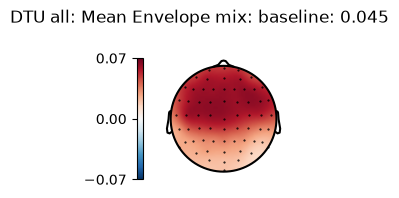

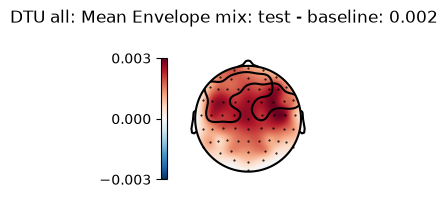

In [94]:
# Envelope mix unique contribution (DTU all)
# Brodbeck et al. 2020 ran this comparison too: mixture envelope unique contribution, t = 5.70, p < .001.
data, diff, result = dtu_model_test('Envelope mix', 'all')
show_topomap_trio(data, diff, result, 'Envelope mix', 'DTU all', None)

In [95]:
display(result)
print(f"Envelope mix (DTU all): TFCE {tfce_summary(result)}")
ttest = test.TTestOneSample(f'roi_{METRIC}', data=diff, tail=1)
print(f"Envelope mix (DTU all): ROI model comparison t({ttest.df}) = {ttest.t:.3f}, p = {ttest.p:.4f}")

<TTestRelated 'r', 'model', 'test', 'baseline', 'subject' (n=18), tail=1, samples=10000, tfce=True, p < .001>

Envelope mix (DTU all): TFCE t_max = 6.25, p < 0.001
Envelope mix (DTU all): ROI model comparison t(17) = 4.921, p = 0.0001


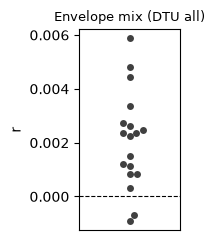

In [96]:
p = show_subject_swarm(diff, 'Envelope mix', 'DTU all')

<small>

**Brodbeck et al. 2020: Two talkers, STRFs (mix, attend, ignore)**

- Onsets: same positive-then-negative shape as for clean speech
- Positive peak: earliest and biggest for the mixture
- Negative peak: only for the mixture and the attended speaker, none for the ignored speaker
- Envelope: lower amplitude, but a strong attention effect (attended > ignored)

</small>

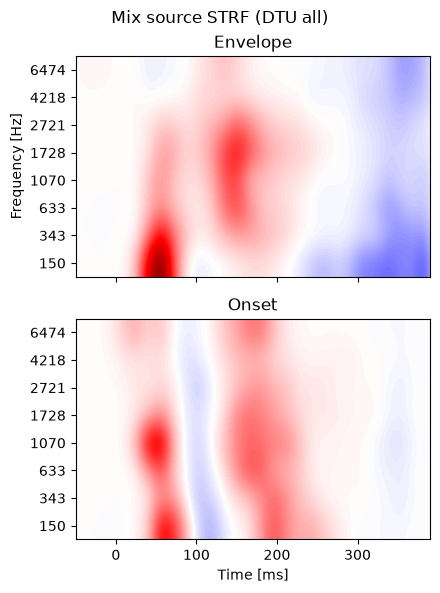

In [97]:
# Mix source STRF: envelope + onset (DTU all)
envelope_strf = extract_strf(data_full, 'mix_gammatone_8')
onset_strf = extract_strf(data_full, 'mix_gammatone_on_8')
p = plot.Array([envelope_strf * 1e3, onset_strf * 1e3], axtitle=['Envelope', 'Onset'],
                title='Mix source STRF (DTU all)', interpolation=STRF_INTERPOLATION, xlim=PLOT_WINDOW)

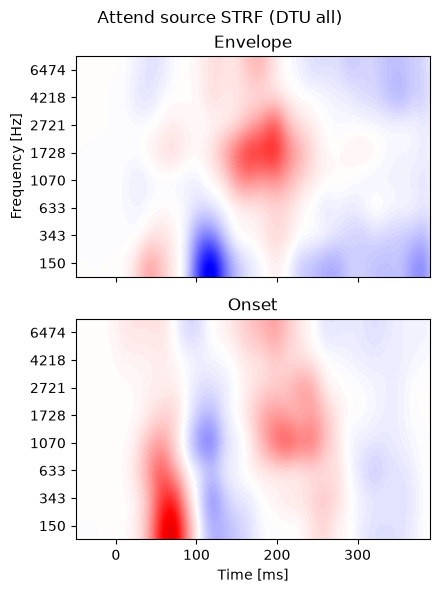

In [98]:
# Attend source STRF: envelope + onset (DTU all)
envelope_strf = extract_strf(data_full, 'gammatone_8')
onset_strf = extract_strf(data_full, 'gammatone_on_8')
p = plot.Array([envelope_strf * 1e3, onset_strf * 1e3], axtitle=['Envelope', 'Onset'],
                title='Attend source STRF (DTU all)', interpolation=STRF_INTERPOLATION, xlim=PLOT_WINDOW)

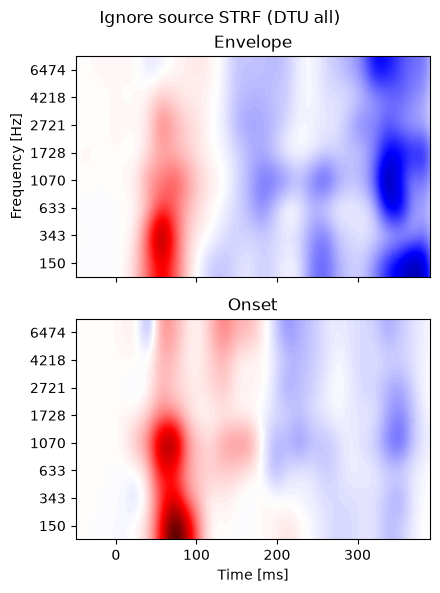

In [99]:
# Ignore source STRF: envelope + onset (DTU all)
envelope_strf = extract_strf(data_full, 'bg_gammatone_8')
onset_strf = extract_strf(data_full, 'bg_gammatone_on_8')
p = plot.Array([envelope_strf * 1e3, onset_strf * 1e3], axtitle=['Envelope', 'Onset'],
                title='Ignore source STRF (DTU all)', interpolation=STRF_INTERPOLATION, xlim=PLOT_WINDOW)

<small>

**Brodbeck et al. 2020: Two talkers, onset peak latencies**

- Positive peak: mixture 72 ms, attended 81 ms, ignored 89 ms
- Negative peak: mixture 136 ms, attended 150 ms, ignored none
- Peak search window: 20 to 200 ms (this notebook: the same)

</small>

In [100]:
# Onset attend peak amplitude & timing (DTU all)
data = extract_trf(data_full, 'gammatone_on_8')
data = add_anchored_peak(data, 'positive', ONSET_POSITIVE_PEAK_WINDOW, kind='max')
data = add_anchored_peak(data, 'negative', ONSET_NEGATIVE_PEAK_WINDOW, kind='min')
print(f"Onset attend (DTU all) positive peak: {data['positive_time'].mean() * 1e3:.0f} ms, amp {data['positive_amp'].mean():.4g}")
print(f"Onset attend (DTU all) negative peak: {data['negative_time'].mean() * 1e3:.0f} ms, amp {data['negative_amp'].mean():.4g}")

Onset attend (DTU all) positive peak: 63 ms, amp 0.003539
Onset attend (DTU all) negative peak: 119 ms, amp -0.001847


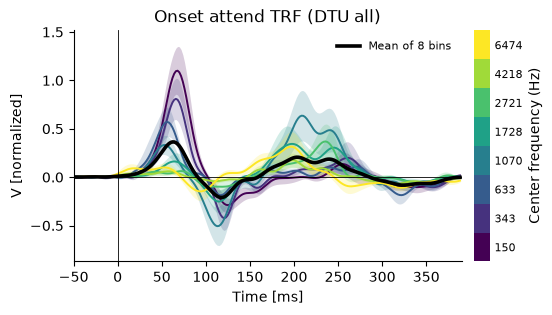

In [101]:
# Onset attend TRF per frequency bin (DTU all)
p = plot_trf_bins(data_full, 'gammatone_on_8', 'Onset attend TRF (DTU all)')

In [102]:
# Onset ignore peak amplitude & timing (DTU all)
data = extract_trf(data_full, 'bg_gammatone_on_8')
data = add_anchored_peak(data, 'positive', ONSET_POSITIVE_PEAK_WINDOW, kind='max')
data = add_anchored_peak(data, 'negative', ONSET_NEGATIVE_PEAK_WINDOW, kind='min')
print(f"Onset ignore (DTU all) positive peak: {data['positive_time'].mean() * 1e3:.0f} ms, amp {data['positive_amp'].mean():.4g}")
print(f"Onset ignore (DTU all) negative peak: {data['negative_time'].mean() * 1e3:.0f} ms, amp {data['negative_amp'].mean():.4g}")

Onset ignore (DTU all) positive peak: 65 ms, amp 0.003029
Onset ignore (DTU all) negative peak: 194 ms, amp -0.0004698


/Users/joshuaighalo/Github Repositories/cocktail-cortical/analysis/experiment.py:2404: UserWarning: negative anchor (all) at 199 ms is on the edge of the search window (0.02, 0.2)
  warnings.warn(f"{name} anchor ({label}) at {times[i] * 1e3:.0f} ms is on the edge of the search window {window}")


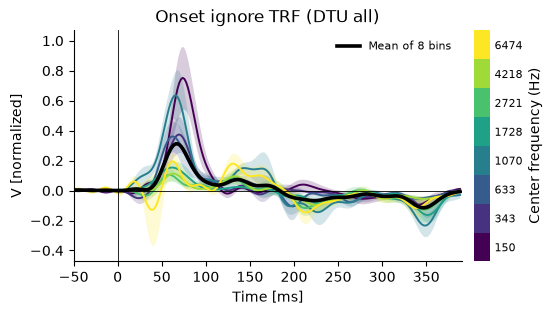

In [103]:
# Onset ignore TRF per frequency bin (DTU all)
p = plot_trf_bins(data_full, 'bg_gammatone_on_8', 'Onset ignore TRF (DTU all)')

In [104]:
# Onset mix peak amplitude & timing (DTU all)
data = extract_trf(data_full, 'mix_gammatone_on_8')
data = add_anchored_peak(data, 'positive', ONSET_POSITIVE_PEAK_WINDOW, kind='max')
data = add_anchored_peak(data, 'negative', ONSET_NEGATIVE_PEAK_WINDOW, kind='min')
print(f"Onset mix (DTU all) positive peak: {data['positive_time'].mean() * 1e3:.0f} ms, amp {data['positive_amp'].mean():.4g}")
print(f"Onset mix (DTU all) negative peak: {data['negative_time'].mean() * 1e3:.0f} ms, amp {data['negative_amp'].mean():.4g}")

Onset mix (DTU all) positive peak: 58 ms, amp 0.00631
Onset mix (DTU all) negative peak: 108 ms, amp -0.00173


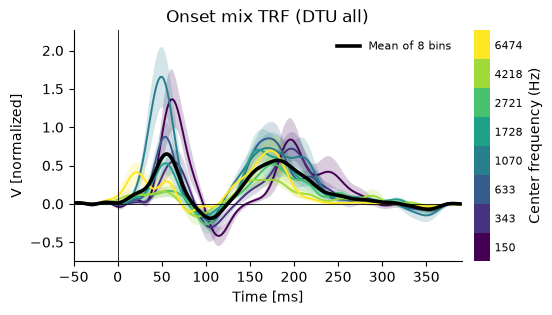

In [105]:
# Onset mix TRF per frequency bin (DTU all)
p = plot_trf_bins(data_full, 'mix_gammatone_on_8', 'Onset mix TRF (DTU all)')

<small>

**Brodbeck et al. 2020: Two talkers, envelope peaks**

- No envelope peak latencies reported; only the attention effect (see the attention-effect cell below)

</small>

In [106]:
# Envelope attend peak amplitude & timing (DTU all)
data = extract_trf(data_full, 'gammatone_8')
data = add_anchored_peak(data, 'positive', ENVELOPE_POSITIVE_PEAK_WINDOW, kind='max')
data = add_anchored_peak(data, 'negative', ENVELOPE_NEGATIVE_PEAK_WINDOW, kind='min')
print(f"Envelope attend (DTU all) positive peak: {data['positive_time'].mean() * 1e3:.0f} ms, amp {data['positive_amp'].mean():.4g}")
print(f"Envelope attend (DTU all) negative peak: {data['negative_time'].mean() * 1e3:.0f} ms, amp {data['negative_amp'].mean():.4g}")

Envelope attend (DTU all) positive peak: 188 ms, amp 0.002815
Envelope attend (DTU all) negative peak: 110 ms, amp -0.001846


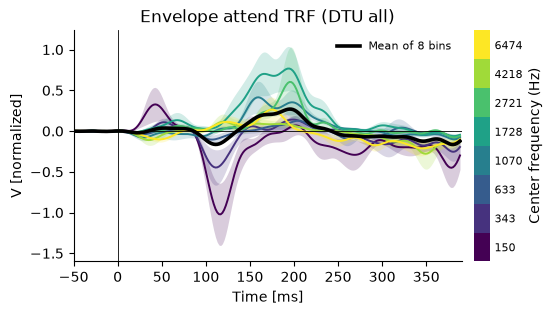

In [107]:
# Envelope attend TRF per frequency bin (DTU all)
p = plot_trf_bins(data_full, 'gammatone_8', 'Envelope attend TRF (DTU all)')

In [108]:
# Envelope ignore peak amplitude & timing (DTU all)
data = extract_trf(data_full, 'bg_gammatone_8')
data = add_anchored_peak(data, 'positive', ENVELOPE_POSITIVE_PEAK_WINDOW, kind='max')
data = add_anchored_peak(data, 'negative', ENVELOPE_NEGATIVE_PEAK_WINDOW, kind='min')
print(f"Envelope ignore (DTU all) positive peak: {data['positive_time'].mean() * 1e3:.0f} ms, amp {data['positive_amp'].mean():.4g}")
print(f"Envelope ignore (DTU all) negative peak: {data['negative_time'].mean() * 1e3:.0f} ms, amp {data['negative_amp'].mean():.4g}")

Envelope ignore (DTU all) positive peak: 60 ms, amp 0.002005
Envelope ignore (DTU all) negative peak: 178 ms, amp -0.00109


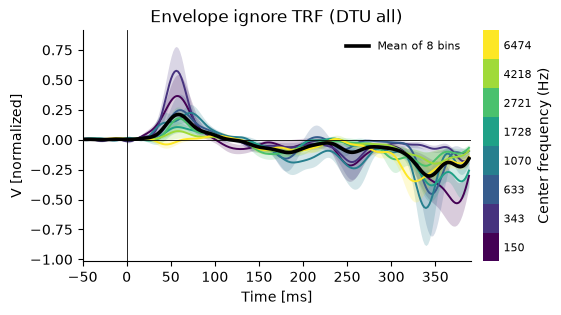

In [109]:
# Envelope ignore TRF per frequency bin (DTU all)
p = plot_trf_bins(data_full, 'bg_gammatone_8', 'Envelope ignore TRF (DTU all)')

In [110]:
# Envelope mix peak amplitude & timing (DTU all)
data = extract_trf(data_full, 'mix_gammatone_8')
data = add_anchored_peak(data, 'positive', ENVELOPE_POSITIVE_PEAK_WINDOW, kind='max')
data = add_anchored_peak(data, 'negative', ENVELOPE_NEGATIVE_PEAK_WINDOW, kind='min')
print(f"Envelope mix (DTU all) positive peak: {data['positive_time'].mean() * 1e3:.0f} ms, amp {data['positive_amp'].mean():.4g}")
print(f"Envelope mix (DTU all) negative peak: {data['negative_time'].mean() * 1e3:.0f} ms, amp {data['negative_amp'].mean():.4g}")

Envelope mix (DTU all) positive peak: 57 ms, amp 0.006185
Envelope mix (DTU all) negative peak: 25 ms, amp 7.058e-05


/Users/joshuaighalo/Github Repositories/cocktail-cortical/analysis/experiment.py:2404: UserWarning: negative anchor (all) at 21 ms is on the edge of the search window (0.02, 0.2)
  warnings.warn(f"{name} anchor ({label}) at {times[i] * 1e3:.0f} ms is on the edge of the search window {window}")


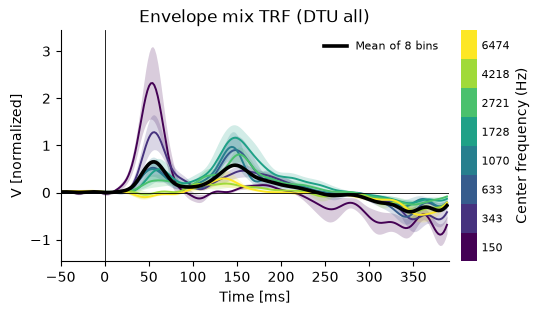

In [111]:
# Envelope mix TRF per frequency bin (DTU all)
p = plot_trf_bins(data_full, 'mix_gammatone_8', 'Envelope mix TRF (DTU all)')

<small>

**Brodbeck et al. 2020: Two talkers, onset peak comparison**

- Positive peak later for attended than mixture: 81 vs 72 ms, t(25) = 4.47, p < 0.001
- Positive peak later for ignored than mixture: 89 vs 72 ms, t(25) = 6.92, p < 0.001
- Positive peak bigger for mixture than attended: t(25) = 8.41, p < 0.001
- Positive peak bigger for mixture than ignored: t(25) = 7.66, p < 0.001
- Negative peak later for attended than mixture: 150 vs 136 ms, t(25) = 3.20, p = 0.004
- Negative peak amplitude: no difference (mixture vs attended), t(25) = 1.56, p = 0.132

</small>

In [112]:
# Onset peak comparison across mix, attend, and ignore (DTU all)
# Brodbeck et al. 2020 ran this comparison too: positive peak latency mixture 72ms, attended 81ms (t=4.47,p<.001), ignored 89ms (t=6.92,p<.001); negative peak latency mixture 138ms, attended 150ms (t=3.20,p=.004); positive peak amplitude bigger for mixture than attended (t=8.41) or ignored (t=7.66).
dss = []
for role_name, column in (('mix', 'mix_gammatone_on_8'), ('attend', 'gammatone_on_8'), ('ignore', 'bg_gammatone_on_8')):
    ds = extract_trf(data_full, column)
    ds[:, 'role'] = role_name
    dss.append(ds)
data = combine(dss)
data = add_anchored_peak(data, 'positive', ONSET_POSITIVE_PEAK_WINDOW, kind='max', by='role')
data = add_anchored_peak(data, 'negative', ONSET_NEGATIVE_PEAK_WINDOW, kind='min', by='role')

/Users/joshuaighalo/Github Repositories/cocktail-cortical/analysis/experiment.py:2404: UserWarning: negative anchor (ignore) at 199 ms is on the edge of the search window (0.02, 0.2)
  warnings.warn(f"{name} anchor ({label}) at {times[i] * 1e3:.0f} ms is on the edge of the search window {window}")


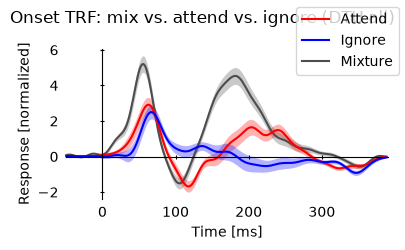

In [113]:
# The onset TRF waveform mix/attend/ignore were each just measured
# from, overlaid so their shape and relative timing are visible
# directly, not just as extracted peak numbers below.
p = plot.UTSStat('trf_sm*1e3', 'role', data=data, match='subject', within_subject_error=True, frame='t', h=2.5, w=4, xlim=PLOT_WINDOW,
                  title='Onset TRF: mix vs. attend vs. ignore (DTU all)', labels=LABELS_ROLE, colors=COLORS_ROLE)

In [114]:
print_peak_table(data, 'positive', 'role')
print_peak_table(data, 'negative', 'role')


positive peak
subject   role         time (ms)           amp
S1        mix                 54      0.007261
S2        mix                 56       0.01181
S3        mix                 70      0.006524
S4        mix                 62         0.012
S5        mix                 70       0.00616
S6        mix                 66      0.003801
S7        mix                 66       0.00171
S8        mix                 45       0.00953
S9        mix                 48      0.008804
S10       mix                 33      0.006273
S11       mix                 52      0.001196
S12       mix                 72       0.00152
S13       mix                 54        0.0031
S14       mix                 60      0.009881
S15       mix                 50       0.01032
S16       mix                 54      0.007493
S17       mix                 78     0.0003736
S18       mix                 56      0.005816
S1        attend              66       0.00338
S2        attend              60      0.00599

In [115]:
display(test.pairwise('positive_time', 'role', match='subject', data=data, corr=False, title='onset positive peak latency: mix vs. attend vs. ignore'))
display(test.pairwise('negative_time', 'role', match='subject', data=data, corr=False, title='onset negative peak latency: mix vs. attend vs. ignore'))

,attend,ignore
mix,t17 = -1.70 p = .107,t17 = -2.65* p = .017
attend,,t17 = -1.00 p = .332


,attend,ignore
mix,t17 = -5.86*** p < .001,t17 = -49.62*** p < .001
attend,,t17 = -34.40*** p < .001


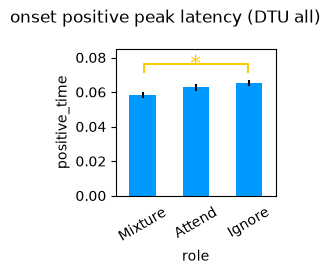

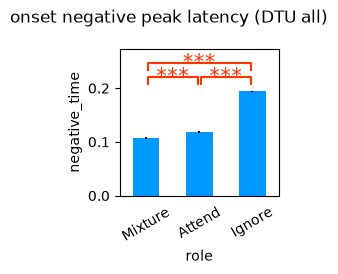

In [116]:
p = plot.Barplot('positive_time', 'role', match='subject', data=data, h=2.5, w=2.5, labels=LABELS_ROLE, corr=False, title='onset positive peak latency (DTU all)')
p.set_xtick_rotation(30)
p = plot.Barplot('negative_time', 'role', match='subject', data=data, h=2.5, w=2.5, labels=LABELS_ROLE, corr=False, title='onset negative peak latency (DTU all)')
p.set_xtick_rotation(30)

In [117]:
display(test.pairwise('positive_amp', 'role', match='subject', data=data, corr=False, title='onset positive peak amplitude: mix vs. attend vs. ignore'))
display(test.pairwise('negative_amp', 'role', match='subject', data=data, corr=False, title='onset negative peak amplitude: mix vs. attend vs. ignore'))

,attend,ignore
mix,t17 = 3.61** p = .002,t17 = 4.85*** p < .001
attend,,t17 = 0.94 p = .359


,attend,ignore
mix,t17 = 0.22 p = .830,t17 = -1.89 p = .076
attend,,t17 = -2.27* p = .037


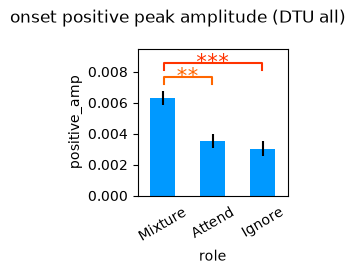

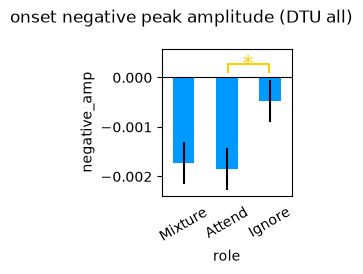

In [118]:
p = plot.Barplot('positive_amp', 'role', match='subject', data=data, h=2.5, w=2.5, labels=LABELS_ROLE, corr=False, title='onset positive peak amplitude (DTU all)')
p.set_xtick_rotation(30)
p = plot.Barplot('negative_amp', 'role', match='subject', data=data, h=2.5, w=2.5, labels=LABELS_ROLE, corr=False, title='onset negative peak amplitude (DTU all)')
p.set_xtick_rotation(30)

<small>

**Brodbeck et al. 2020: Two talkers, envelope peak comparison**

- No envelope peak comparison reported

</small>

In [119]:
# Envelope peak comparison across mix, attend, and ignore (DTU all)
dss = []
for role_name, column in (('mix', 'mix_gammatone_8'), ('attend', 'gammatone_8'), ('ignore', 'bg_gammatone_8')):
    ds = extract_trf(data_full, column)
    ds[:, 'role'] = role_name
    dss.append(ds)
data = combine(dss)
data = add_anchored_peak(data, 'positive', ENVELOPE_POSITIVE_PEAK_WINDOW, kind='max', by='role')
data = add_anchored_peak(data, 'negative', ENVELOPE_NEGATIVE_PEAK_WINDOW, kind='min', by='role')

/Users/joshuaighalo/Github Repositories/cocktail-cortical/analysis/experiment.py:2404: UserWarning: negative anchor (mix) at 21 ms is on the edge of the search window (0.02, 0.2)
  warnings.warn(f"{name} anchor ({label}) at {times[i] * 1e3:.0f} ms is on the edge of the search window {window}")


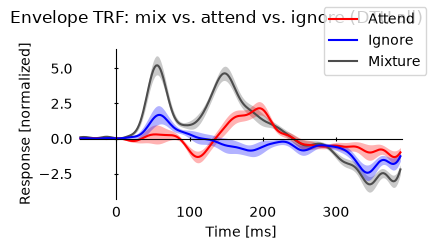

In [120]:
# The envelope TRF waveform mix/attend/ignore were each just measured
# from, overlaid so their shape and relative timing are visible
# directly, not just as extracted peak numbers below.
p = plot.UTSStat('trf_sm*1e3', 'role', data=data, match='subject', within_subject_error=True, frame='t', h=2.5, w=4, xlim=PLOT_WINDOW,
                  title='Envelope TRF: mix vs. attend vs. ignore (DTU all)', labels=LABELS_ROLE, colors=COLORS_ROLE)

In [121]:
print_peak_table(data, 'positive', 'role')
print_peak_table(data, 'negative', 'role')


positive peak
subject   role         time (ms)           amp
S1        mix                 50       0.01448
S2        mix                 70      0.002032
S3        mix                 60       0.01567
S4        mix                 50       0.01216
S5        mix                 70      0.007959
S6        mix                 58      0.005493
S7        mix                 56      0.007014
S8        mix                 45      0.003229
S9        mix                 80      0.001164
S10       mix                 66     3.786e-05
S11       mix                 52     0.0001932
S12       mix                 41      0.002173
S13       mix                 56       0.01313
S14       mix                 64      0.005479
S15       mix                 43      0.007777
S16       mix                 35      0.002201
S17       mix                 80      0.001779
S18       mix                 54      0.009354
S1        attend             175      0.002372
S2        attend             171     0.000760

In [122]:
display(test.pairwise('positive_time', 'role', match='subject', data=data, corr=False, title='envelope positive peak latency: mix vs. attend vs. ignore'))
display(test.pairwise('negative_time', 'role', match='subject', data=data, corr=False, title='envelope negative peak latency: mix vs. attend vs. ignore'))

,attend,ignore
mix,t17 = -28.34*** p < .001,t17 = -1.26 p = .226
attend,,t17 = 32.80*** p < .001


,attend,ignore
mix,t17 = -25.42*** p < .001,t17 = -45.76*** p < .001
attend,,t17 = -13.32*** p < .001


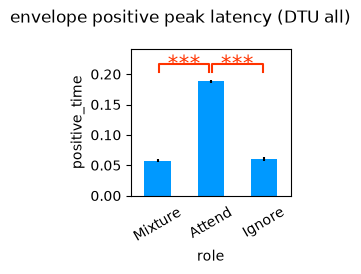

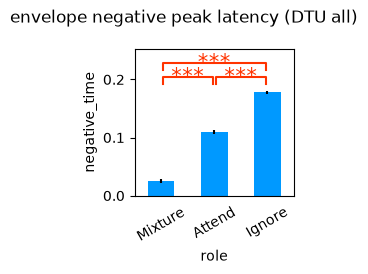

In [123]:
p = plot.Barplot('positive_time', 'role', match='subject', data=data, h=2.5, w=2.5, labels=LABELS_ROLE, corr=False, title='envelope positive peak latency (DTU all)')
p.set_xtick_rotation(30)
p = plot.Barplot('negative_time', 'role', match='subject', data=data, h=2.5, w=2.5, labels=LABELS_ROLE, corr=False, title='envelope negative peak latency (DTU all)')
p.set_xtick_rotation(30)

In [124]:
display(test.pairwise('positive_amp', 'role', match='subject', data=data, corr=False, title='envelope positive peak amplitude: mix vs. attend vs. ignore'))
display(test.pairwise('negative_amp', 'role', match='subject', data=data, corr=False, title='envelope negative peak amplitude: mix vs. attend vs. ignore'))

,attend,ignore
mix,t17 = 2.27* p = .037,t17 = 3.65** p = .002
attend,,t17 = 0.75 p = .463


,attend,ignore
mix,t17 = 3.27** p = .005,t17 = 4.60*** p < .001
attend,,t17 = -1.21 p = .242


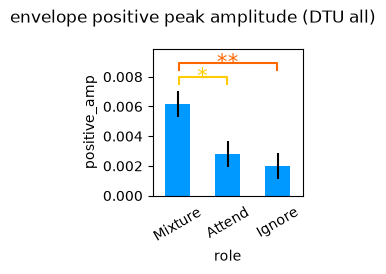

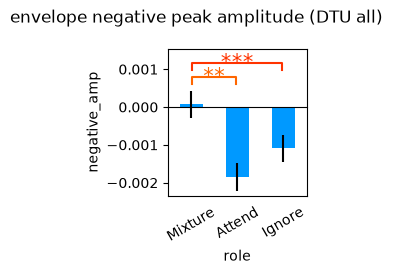

In [125]:
p = plot.Barplot('positive_amp', 'role', match='subject', data=data, h=2.5, w=2.5, labels=LABELS_ROLE, corr=False, title='envelope positive peak amplitude (DTU all)')
p.set_xtick_rotation(30)
p = plot.Barplot('negative_amp', 'role', match='subject', data=data, h=2.5, w=2.5, labels=LABELS_ROLE, corr=False, title='envelope negative peak amplitude (DTU all)')
p.set_xtick_rotation(30)

<small>

**Brodbeck et al. 2020: Two talkers, envelope attention effect (attend - ignore)**

- Negative peak at about 100 ms
- Positive peak at about 200 ms
- The attention effect starts almost as early as the earliest response

</small>

Permutation test:   0%|          | 0/10000 [00:00<?, ? permutations/s]

Envelope attention effect: attend - ignore (DTU all): bins that differ from 0 somewhere: 1070 Hz, 2721 Hz


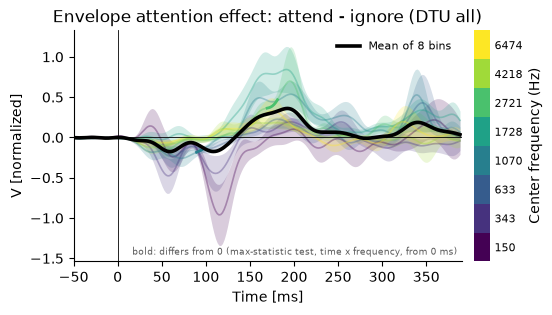

In [126]:
# Envelope attention effect: attend - ignore (DTU all)
# Brodbeck et al. 2020 ran this comparison too: envelope attention-effect difference wave: negative bump ~100ms, positive bump ~200ms, starting almost immediately.
p = plot_trf_bins(data_full, 'gammatone_8', 'Envelope attention effect: attend - ignore (DTU all)', subtract='bg_gammatone_8')

Permutation test:   0%|          | 0/10000 [00:00<?, ? permutations/s]

Envelope attention effect: attend - ignore (DTU all): differs from 0 (max-statistic permutation test from 0 ms, two-tailed; ranges < 10 ms apart joined) at 72-74 ms (p = 0.049); 164-209 ms (p = 0.007)


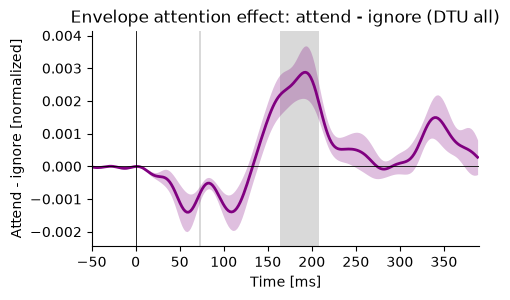

In [127]:
# The same attention effect as one waveform: summed over the frequency bins, mean +- 1 SEM across
# subjects; grey where attend - ignore differs from 0 (TFCE over time, two-tailed).
p = plot_attention_effect(data_full, 'gammatone_8', 'bg_gammatone_8', 'Envelope attention effect: attend - ignore (DTU all)')

<small>

**Brodbeck et al. 2020: Two talkers, onset attention effect (attend - ignore)**

- Early positive peak: little or no attention effect
- Later negative peak (about 136 to 150 ms): attended only, so a clear attention effect there

</small>

Permutation test:   0%|          | 0/10000 [00:00<?, ? permutations/s]

Onset attention effect: attend - ignore (DTU all): bins that differ from 0 somewhere: 343 Hz, 633 Hz


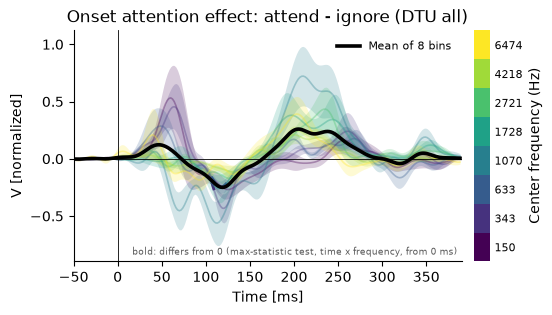

In [128]:
# Onset attention effect: attend - ignore (DTU all)
# Brodbeck et al. 2020 ran this comparison too: onset attention effect appears later than the envelope's, once the masked-onset response develops (see the masked-onset section below).
p = plot_trf_bins(data_full, 'gammatone_on_8', 'Onset attention effect: attend - ignore (DTU all)', subtract='bg_gammatone_on_8')

Permutation test:   0%|          | 0/10000 [00:00<?, ? permutations/s]

Onset attention effect: attend - ignore (DTU all): differs from 0 (max-statistic permutation test from 0 ms, two-tailed; ranges < 10 ms apart joined) at 99-130 ms (p = 0.009); 205-224 ms (p = 0.032); 238-240 ms (p = 0.049)


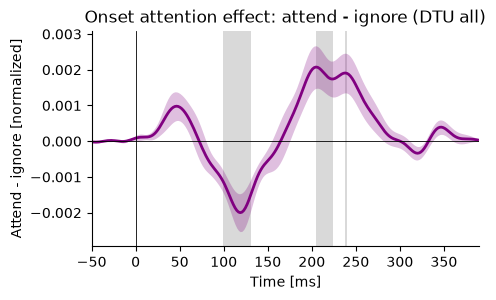

In [129]:
# The same attention effect as one waveform: summed over the frequency bins, mean +- 1 SEM across
# subjects; grey where attend - ignore differs from 0 (TFCE over time, two-tailed).
p = plot_attention_effect(data_full, 'gammatone_on_8', 'bg_gammatone_on_8', 'Onset attention effect: attend - ignore (DTU all)')